### Build A Basic Chatbot With Langgraph(GRAPH API)

In [1]:
from typing import Annotated

from typing_extensions import TypedDict

from langgraph.graph import StateGraph,START,END
from langgraph.graph.message import add_messages

In [2]:
class State(TypedDict):
    # Messages have the type "list". The `add_messages` function
    # in the annotation defines how this state key should be updated
    # (in this case, it appends messages to the list, rather than overwriting them)
    messages:Annotated[list,add_messages]

In [3]:
import os
from dotenv import load_dotenv
load_dotenv()

True

In [4]:
from langchain_groq import ChatGroq
from langchain.chat_models import init_chat_model

llm=ChatGroq(model="openai/gpt-oss-120b")

In [5]:
## Node Functionality
def chatbot(state:State):
    return {"messages":[llm.invoke(state["messages"])]}

In [6]:
graph_builder=StateGraph(State)

## Adding node
graph_builder.add_node("llmchatbot",chatbot)
## Adding Edges
graph_builder.add_edge(START,"llmchatbot")
graph_builder.add_edge("llmchatbot",END)

## compile the graph
graph=graph_builder.compile()

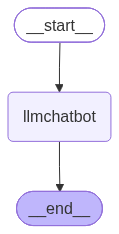

In [7]:
## Visualize the graph
from IPython.display import Image,display

try:
    display(Image(graph.get_graph().draw_mermaid_png()))
except Exception:
    pass

In [8]:
response=graph.invoke({"messages":"Hello!"})

In [9]:
response["messages"][-1].content

'Hello! 👋 How can I assist you today?'

In [10]:
for event in graph.stream({"messages":"Hi How are you?"}):
    for value in event.values():
        print(value["messages"][-1].content)

Hey there! I'm doing great, thanks for asking. How can I help you today?


### Chatbot with Tools

In [11]:
from langchain_tavily import TavilySearch

tool=TavilySearch(max_results=2)
tool.invoke("Who is Nimesh Akarshana?")

{'query': 'Who is Nimesh Akarshana?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://linkedin.com/in/nimesh-akarshana-27619a263',
   'title': 'Nimesh Akarshana',
   'content': '# Nimesh Akarshana\n\nMatara, Southern Province, Sri Lanka, LK  \n500 connections, 1070 followers\n\n## About\nFinal-year Computer Engineering student and AI Engineering Intern who has shipped…\n\n## Experience\nN/A\n\n## Education\n### University of Ruhuna  \nN/A  \n2023-05 - 2026-10  \nNone\n\n### N/A  \nN/A  \n2021-01 - 2022-01  \nNone\n\n### N/A  \nN/A  \n2007 - 2020  \nNone\n\n### N/A  \nN/A  \n2018-01 - 2019-10  \nNone\n\n## Publications\nN/A [...] analytics across sports like football and volleyball. 👥 Team Members: Nimesh Akarshana Nethangi Dissanayake Sanaka Lorensuhewa Happy to collaborate or answer questions! 🚀 #YOLO #OpenCV #Python #SportsAnalytics #DFL #ComputerVision #AIinSports #PlayerTracking #FootballTech #Bundesliga ...more ...more [...] #CambioFamil

In [12]:
## Custom function
def multiply(a:int,b:int)->int:
    """Multiply a and b

    Args:
        a (int): first int
        b (int): second int

    Returns:
        int: output int
    """
    return a*b

In [13]:
tools=[tool,multiply]

In [14]:
llm_with_tool=llm.bind_tools(tools)

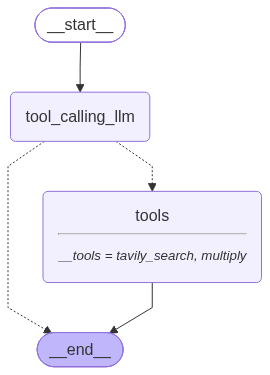

In [15]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools",END)

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [16]:
response=graph.invoke({"messages":"What is the recent ai news"})

In [17]:
response['messages']

[HumanMessage(content='What is the recent ai news', additional_kwargs={}, response_metadata={}, id='ca760fbb-8fb8-494f-a604-1751c750043c'),
 AIMessage(content='', additional_kwargs={'reasoning_content': 'User asks: "What is the recent ai news". Need to provide recent AI news. Likely need up-to-date info. Use search.', 'tool_calls': [{'id': 'fc_a754ad52-bee0-4ade-8799-b771a05ec84f', 'function': {'arguments': '{"query":"latest AI news November 2026","search_depth":"advanced","time_range":"day"}', 'name': 'tavily_search'}, 'type': 'function'}]}, response_metadata={'token_usage': {'completion_tokens': 81, 'prompt_tokens': 348, 'total_tokens': 429, 'completion_time': 0.171428241, 'completion_tokens_details': {'reasoning_tokens': 30}, 'prompt_time': 0.018207353, 'prompt_tokens_details': None, 'queue_time': 0.369613007, 'total_time': 0.189635594}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_8655ddce88', 'service_tier': 'on_demand', 'finish_reason': 'tool_calls', 'logprobs':

In [18]:
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is the recent ai news
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_a754ad52-bee0-4ade-8799-b771a05ec84f)
 Call ID: fc_a754ad52-bee0-4ade-8799-b771a05ec84f
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, November 5: Top Stories | AI Weekly", "content": "AI News Archives Learning AI Newsletters AI Index AI News Today Who's Who Use Cases Advertise Login\n\n AI News Weekly\n\nJoin free with your email\n\nFree. No spam, ever — we'll never share your email address and you can opt out at any time. Already a subscri

In [19]:
response=graph.invoke({"messages":"What is 521 multiplied by 212312"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is 521 multiplied by 212312
================================== Ai Message ==================================
Tool Calls:
  multiply (fc_208af176-98b9-4d74-a81d-67f429f08a60)
 Call ID: fc_208af176-98b9-4d74-a81d-67f429f08a60
  Args:
    a: 521
    b: 212312
================================= Tool Message =================================
Name: multiply

110614552


In [20]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_ae882d11-717d-4633-b31b-cb6ced954f00)
 Call ID: fc_ae882d11-717d-4633-b31b-cb6ced954f00
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: day
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://aiweekly.co/ai-news-today", "title": "AI News Today, November 5: Top Stories | AI Weekly", "content": "AI News Archives Learning AI Newsletters AI Index AI News Today Who's Who Use Cases Advertise Login\n\n AI News Weekly\n\nJoin free with your email\n\nFree. No spam, ever — we'll never share your email address and you can opt out at a

### ReAct Agent Architecure

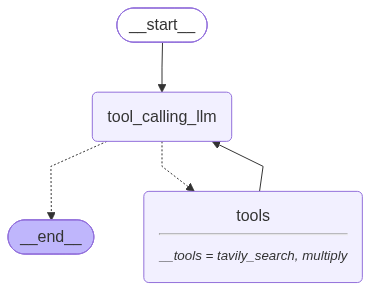

In [21]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile()

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [22]:
response=graph.invoke({"messages":"Give me the recent ai news and then multiply 5 by 10"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Give me the recent ai news and then multiply 5 by 10
================================== Ai Message ==================================
Tool Calls:
  tavily_search (fc_d08eea42-6c4e-4156-8664-42e05ad9f694)
 Call ID: fc_d08eea42-6c4e-4156-8664-42e05ad9f694
  Args:
    query: latest AI news November 2026
    search_depth: advanced
    time_range: week
================================= Tool Message =================================
Name: tavily_search

{"query": "latest AI news November 2026", "follow_up_questions": null, "answer": null, "images": [], "results": [{"url": "https://www.youtube.com/watch?v=ZfrXFzZ7vaM", "title": "What's Coming in AI in November 2026: Kimi Weights, Qwen 4, Grok 4.8, Claude's IPO (November 2026)", "content": "# What's Coming in AI in November 2026: Kimi Weights, Qwen 4, Grok 4.8, Claude's IPO (November 2026)\n## Channel: StudyZoom international\n23.1K subscribers\n0 likes\n\n### De

## Adding Memory In Agentic Graph

In [23]:
response=graph.invoke({"messages":"Hello my name is Nimesh"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

Hello my name is Nimesh
================================== Ai Message ==================================

Hello Nimesh! Nice to meet you. How can I help you today?


In [24]:
response=graph.invoke({"messages":"What is my name"})
for m in response['messages']:
    m.pretty_print()

================================ Human Message =================================

What is my name
================================== Ai Message ==================================

I’m not able to see your name from our conversation, so I don’t know it. If you’d like me to address you by a specific name, just let me know!


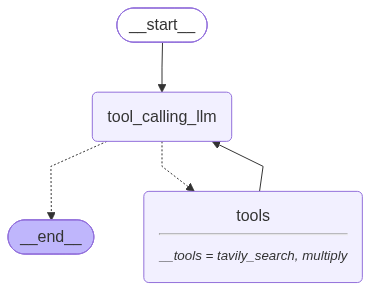

In [25]:
## Stategraph
from langgraph.graph import StateGraph,START,END
from langgraph.prebuilt import ToolNode
from langgraph.prebuilt import tools_condition
from langgraph.checkpoint.memory import MemorySaver

memory = MemorySaver()

## Node definition
def tool_calling_llm(state:State):
    return {"messages":[llm_with_tool.invoke(state["messages"])]}

## Grpah
builder=StateGraph(State)
builder.add_node("tool_calling_llm",tool_calling_llm)
builder.add_node("tools",ToolNode(tools))

## Add Edges
builder.add_edge(START, "tool_calling_llm")
builder.add_conditional_edges(
    "tool_calling_llm",
    # If the latest message (result) from assistant is a tool call -> tools_condition routes to tools
    # If the latest message (result) from assistant is a not a tool call -> tools_condition routes to END
    tools_condition
)
builder.add_edge("tools","tool_calling_llm")

## compile the graph
graph=builder.compile(checkpointer=memory)

from IPython.display import Image, display
display(Image(graph.get_graph().draw_mermaid_png()))

In [26]:
config={"configurable":{"thread_id":"123"}}

In [27]:
response=graph.invoke({"messages":"Hi my name is Nimesh"},config=config)

In [28]:
response["messages"][-1].content

'Hello Nimesh! Nice to meet you. How can I assist you today?'

In [29]:
response=graph.invoke({"messages":"What is my name?"},config=config)


In [30]:
response["messages"][-1].content

'Your name is Nimesh.'

Streaming
Methods: .stream() and astream()

These methods are sync and async methods for streaming back results.
Additional parameters in streaming modes for graph state

values : This streams the full state of the graph after each node is called.
updates : This streams updates to the state of the graph after each node is called.

In [32]:
from langgraph.checkpoint.memory import MemorySaver
memory=MemorySaver()


In [33]:
def superbot(state:State):
    return {"messages":[llm.invoke(state['messages'])]}

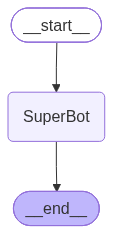

In [34]:
graph=StateGraph(State)

## node
graph.add_node("SuperBot",superbot)
## Edges

graph.add_edge(START,"SuperBot")
graph.add_edge("SuperBot",END)


graph_builder=graph.compile(checkpointer=memory)


## Display
from IPython.display import Image, display
display(Image(graph_builder.get_graph().draw_mermaid_png()))

In [35]:
## Invocation

config = {"configurable": {"thread_id": "1"}}

graph_builder.invoke({'messages':"Hi,My name is Krish And I like cricket"},config)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='b8e07fc6-3235-40a4-ad1f-a8f0a6cd3933'),
  AIMessage(content="Hello Krish! 👋 Great to meet you.  \n\nCricket is such an exciting sport—do you have a favorite team or player? Are you more into Test matches, ODIs, or the fast‑paced thrill of T20s? I'd love to hear what you enjoy most about the game!", additional_kwargs={'reasoning_content': 'The user says "Hi, My name is Krish And I like cricket". Likely they want a response. We should greet them, ask about cricket preferences. Keep friendly.'}, response_metadata={'token_usage': {'completion_tokens': 108, 'prompt_tokens': 82, 'total_tokens': 190, 'completion_time': 0.227984605, 'completion_tokens_details': {'reasoning_tokens': 37}, 'prompt_time': 0.013974296, 'prompt_tokens_details': None, 'queue_time': 0.372672133, 'total_time': 0.241958901}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_803c0ba83d

In [36]:
# Create a thread
config = {"configurable": {"thread_id": "3"}}

for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="updates"):
    print(chunk)

{'SuperBot': {'messages': [AIMessage(content='Hello Krish! 👋 Nice to meet you.  \n\nCricket’s such a fun sport—do you have a favorite team or player? Are you more into the fast‑bowling action, the strategic spin game, or maybe the excitement of T20 leagues? Let’s chat about it!', additional_kwargs={'reasoning_content': 'The user says hi, introduces themselves. The assistant should respond friendly, perhaps ask about cricket preferences, etc. No policy issues. Provide a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 82, 'total_tokens': 183, 'completion_time': 0.207523782, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.003192869, 'prompt_tokens_details': None, 'queue_time': 0.370745156, 'total_time': 0.210716651}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp_e5b4e54fbb', 'service_tier': 'on_demand', 'finish_reason': 'stop', 'logprobs': None, 'model_provider': 'groq'}, id='lc_run--01a1af48-a45e

In [37]:
for chunk in graph_builder.stream({'messages':"Hi,My name is Krish And I like cricket"},config,stream_mode="values"):
    print(chunk)

{'messages': [HumanMessage(content='Hi,My name is Krish And I like cricket', additional_kwargs={}, response_metadata={}, id='a9503fb0-a987-455d-8e81-b8afd0eef682'), AIMessage(content='Hello Krish! 👋 Nice to meet you.  \n\nCricket’s such a fun sport—do you have a favorite team or player? Are you more into the fast‑bowling action, the strategic spin game, or maybe the excitement of T20 leagues? Let’s chat about it!', additional_kwargs={'reasoning_content': 'The user says hi, introduces themselves. The assistant should respond friendly, perhaps ask about cricket preferences, etc. No policy issues. Provide a friendly response.'}, response_metadata={'token_usage': {'completion_tokens': 101, 'prompt_tokens': 82, 'total_tokens': 183, 'completion_time': 0.207523782, 'completion_tokens_details': {'reasoning_tokens': 32}, 'prompt_time': 0.003192869, 'prompt_tokens_details': None, 'queue_time': 0.370745156, 'total_time': 0.210716651}, 'model_name': 'openai/gpt-oss-120b', 'system_fingerprint': 'fp